<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_haftal%C4%B1kg%C3%B6rev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Using Colab cache for faster access to the 'traffic-signs-dataset-germany-uk-usa' dataset.
Bulunan görsel sayısı: 2614


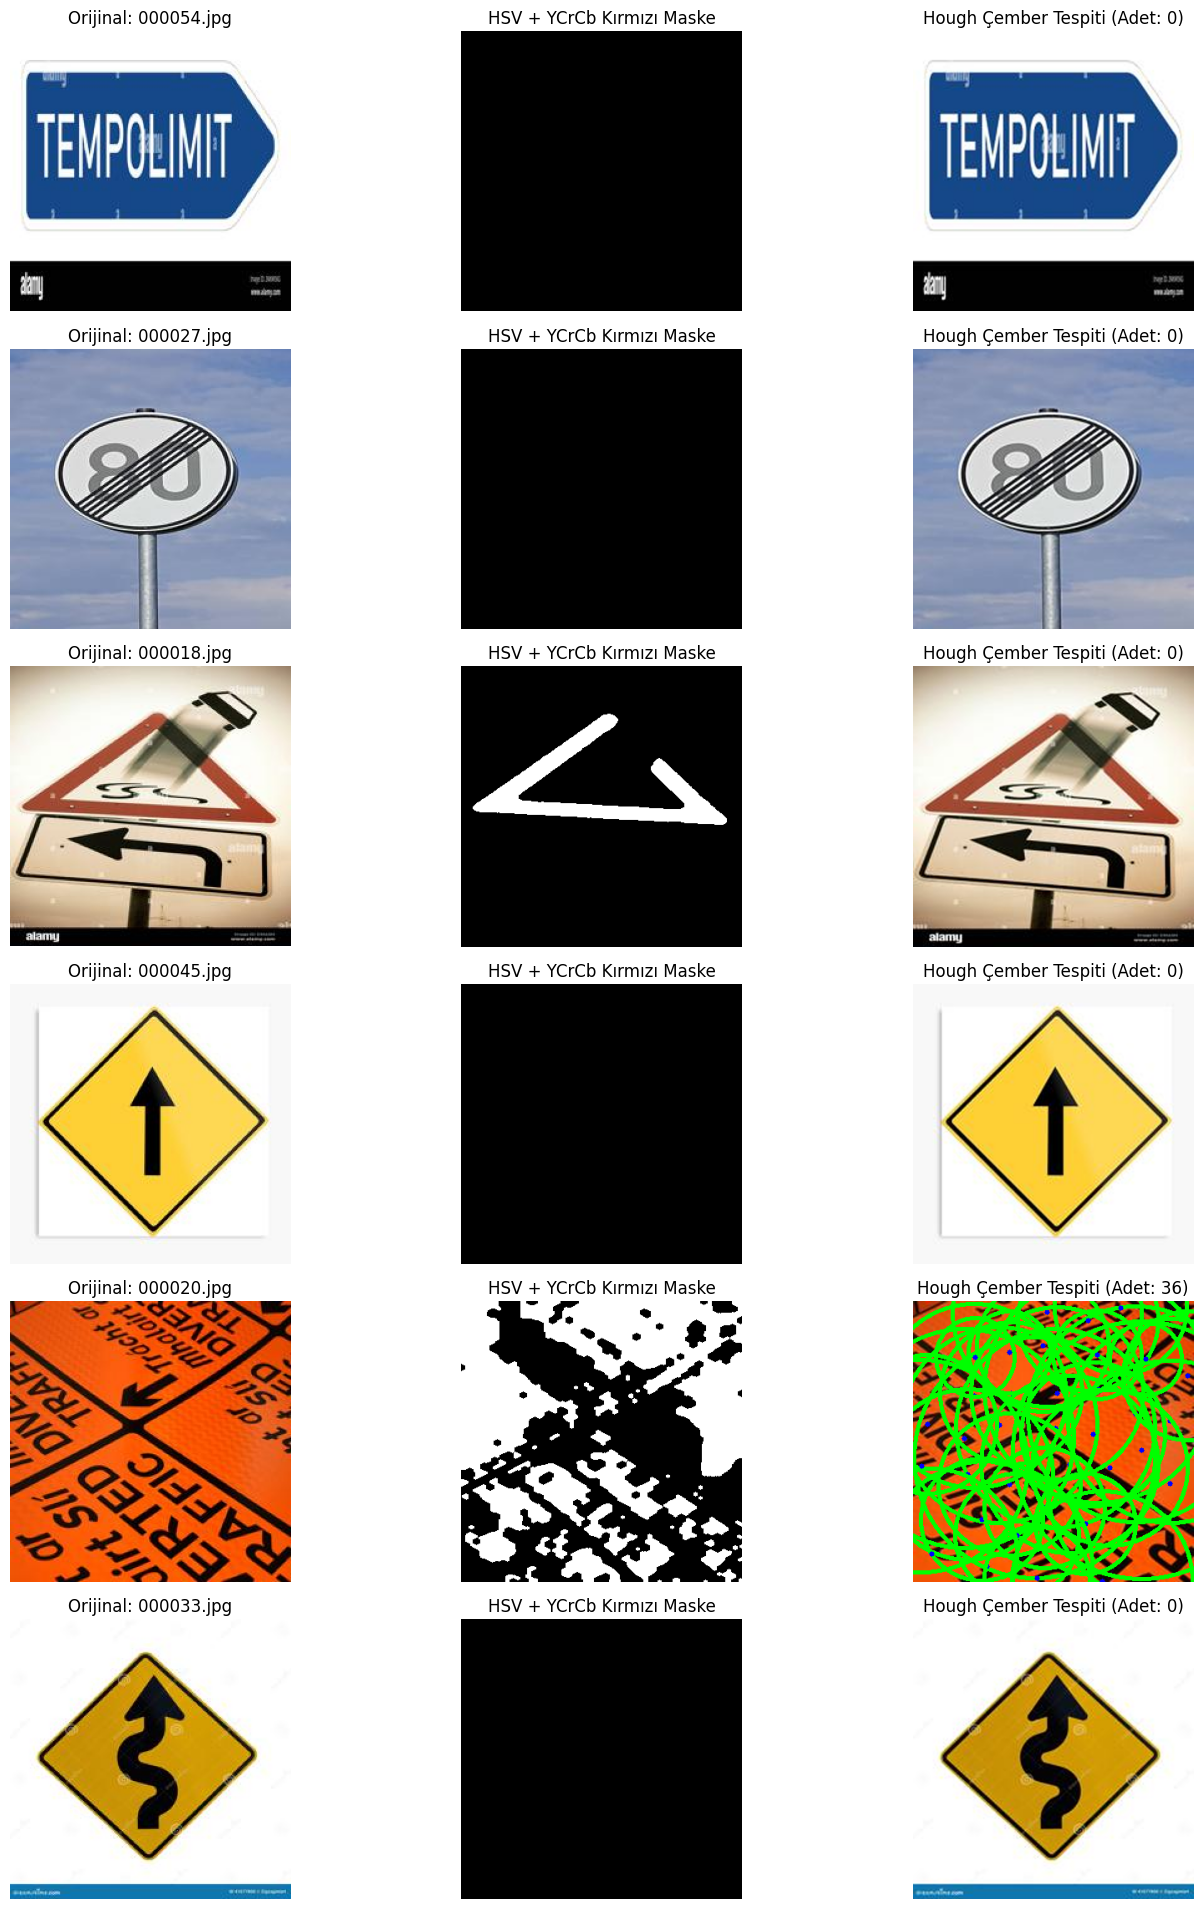

In [3]:
import glob
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_paths = []
try:
    import kagglehub
    dataset_path = kagglehub.dataset_download("tabishalam0/traffic-signs-dataset-germany-uk-usa")
    for ext in ("*.png", "*.jpg", "*.jpeg", "*.ppm"):
        image_paths.extend(glob.glob(os.path.join(dataset_path, "**", ext), recursive=True))
except Exception as e:
    print("kagglehub ile indirme yapılmadı/atlanıyor:", e)
    for ext in ("*.png", "*.jpg", "*.jpeg", "*.ppm"):
        image_paths.extend(glob.glob(os.path.join(".", "**", ext), recursive=True))

print(f"Bulunan görsel sayısı: {len(image_paths)}")

def kırmızı_cember_isaret_tespit(bgr_img):
    """
    HSV ve YCrCb renk uzaylarını birlikte kullanarak kırmızı bölgeleri maskeler
    ve Hough Circles ile kırmızı çember içeren trafik işaretlerini tespit eder.
    """
    h, w = bgr_img.shape[:2]
    scale = 4.0 if max(h, w) < 120 else 1.5
    resized = cv2.resize(bgr_img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_CUBIC)

    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    mask_hsv1 = cv2.inRange(hsv, np.array([0, 70, 50]), np.array([12, 255, 255]))
    mask_hsv2 = cv2.inRange(hsv, np.array([168, 70, 50]), np.array([180, 255, 255]))
    mask_hsv = cv2.bitwise_or(mask_hsv1, mask_hsv2)

    ycrcb = cv2.cvtColor(resized, cv2.COLOR_BGR2YCrCb)
    mask_ycrcb = cv2.inRange(ycrcb, np.array([40, 145, 70]), np.array([255, 230, 145]))

    red_mask = cv2.bitwise_and(mask_hsv, mask_ycrcb)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    blurred = cv2.GaussianBlur(red_mask, (9, 9), 2)
    min_r = max(12, int(min(resized.shape[:2]) * 0.12))
    max_r = int(min(resized.shape[:2]) * 0.48)

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=max(20, min_r),
        param1=80,
        param2=18,
        minRadius=min_r,
        maxRadius=max_r
    )

    vis = resized.copy()
    detected_count = 0
    if circles is not None:
        circles_int = np.uint16(np.around(circles[0, :]))
        for (cx, cy, r) in circles_int:
            ring_mask = np.zeros_like(red_mask)
            cv2.circle(ring_mask, (cx, cy), r, 255, thickness=max(3, int(r * 0.18)))
            ring_pixels = np.count_nonzero(ring_mask)
            red_on_ring = np.count_nonzero(cv2.bitwise_and(red_mask, ring_mask))
            ratio = red_on_ring / max(ring_pixels, 1)

            if ratio >= 0.35:
                detected_count += 1
                cv2.circle(vis, (cx, cy), r, (0, 255, 0), 3)
                cv2.circle(vis, (cx, cy), 3, (255, 0, 0), -1)

    return vis, red_mask, detected_count

sample_imgs = []
if len(image_paths) > 0:
    np.random.seed(42)
    chosen = np.random.choice(image_paths, size=min(6, len(image_paths)), replace=False)
    for p in chosen:
        im = cv2.imread(p)
        if im is not None:
            sample_imgs.append((os.path.basename(p), im))
else:
    syn = np.full((120, 120, 3), (220, 220, 220), dtype=np.uint8)
    cv2.circle(syn, (60, 60), 42, (0, 0, 220), 10)
    sample_imgs.append(("sentetik_isaret.png", syn))

plt.figure(figsize=(15, len(sample_imgs) * 3.2))
for idx, (name, im) in enumerate(sample_imgs):
    vis_out, r_mask, cnt = kırmızı_cember_isaret_tespit(im)

    plt.subplot(len(sample_imgs), 3, idx * 3 + 1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title(f"Orijinal: {name}")
    plt.axis("off")

    plt.subplot(len(sample_imgs), 3, idx * 3 + 2)
    plt.imshow(r_mask, cmap="gray")
    plt.title("HSV + YCrCb Kırmızı Maske")
    plt.axis("off")

    plt.subplot(len(sample_imgs), 3, idx * 3 + 3)
    plt.imshow(cv2.cvtColor(vis_out, cv2.COLOR_BGR2RGB))
    plt.title(f"Hough Çember Tespiti (Adet: {cnt})")
    plt.axis("off")

plt.tight_layout()
plt.show()